In [1]:
import utils
import xarray as xr
import numpy as np
import dask
from distributed import Client
from dask.distributed import wait
from ncar_jobqueue import NCARCluster
from glob import glob
import intake
import importlib
import pop_tools
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
xr.set_options(keep_attrs=True)

## Spin up DASK cluster

In [2]:
def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=2,
        memory='100 GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=100GB',
        project='NCGD0011',
        walltime='02:00:00',
        interface='ext',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

In [3]:
cluster, client = get_ClusterClient()
cluster.scale(20) 
client

Client Scheduler: tcp://128.117.208.174:44637 Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Cluster Workers: 0 Cores: 0 Memory: 0 B


## Define some functions we'll need to load data

In [4]:
# define the metrics we can load 
metrics_dict = {
    "NPP": ['photoC_TOT_zint'],
    "Zooplankton Production": ['graze_diat_zint', 'graze_sp_zint'],
    "Diatom fraction (biomass)": ['diatC', 'spC'],
    "Mesozoo production": ['graze_diat_zint', 'graze_sp_zint', 'diatC', 'spC'],
    "Mesozooplankton biomass": ['zooC', 'diatC', 'spC', 'graze_diat_zint', 'graze_sp_zint'],
    "Trophic Level 3": ['graze_diat_zint', 'graze_sp_zint', 'diatC', 'spC'],
    "Krill Growth Potential": ['TEMP','diatChl','spChl','diazChl']
}

def get_metrics_list():
    return list(metrics_dict.keys())

In [5]:
# function to return the variables we need to return for all metrics
def get_metric_variable(metric):
    var_names = metrics_dict[metric]
    # handle the case where there is only one variable
    if isinstance(var_names, str):
        return var_names
    # handle the case where there are multiple variables
    else:
        return var_names[:]

In [6]:
# function to average over top 150m for relevant variables and to keep time bound
def preprocess(ds):
    tb = ds.time_bound
    # check if relevant variables are in dataset, and if so, average over the dimension
    if hasattr(ds,'TEMP'):
        print('getting top level (500cm) temperature')
        temp = ds.TEMP
        ds['TEMP'] = temp.isel(z_t=0)
        ds['TEMP'].attrs['long_name'] = 'ocean temperature, surface (500cm)'
        del(temp)    
    if hasattr(ds,'diatChl'):
        print('getting top level (500cm) diatom chlorophyll')
        temp = ds.diatChl
        ds['diatChl'] = temp.isel(z_t_150m=0)
        ds['diatChl'].attrs['long_name'] = 'diatom chlorophyll, surface (500cm)'
        del(temp) 
    if hasattr(ds,'diazChl'):
        print('getting top level (500cm) diazatroph chlorophyll')
        temp = ds.diazChl
        ds['diazChl'] = temp.isel(z_t_150m=0)
        ds['diazChl'].attrs['long_name'] = 'diazatroph chlorophyll, surface (500cm)'
        del(temp)         
    if hasattr(ds,'spChl'):
        print('getting top level (500cm) small phytoplankton chlorophyll')
        temp = ds.spChl
        ds['spChl'] = temp.isel(z_t_150m=0)
        ds['spChl'].attrs['long_name'] = 'small phytoplankton chlorophyll, surface (500cm)'
        del(temp)         
    if hasattr(ds,'diatC'):
        print('averaging diatC over top 150m')
        temp = ds.diatC
        ds['diatC'] = temp.mean(dim='z_t_150m')
        ds['diatC'].attrs['long_name'] = 'diatom plankton carbon, top 150m mean'
        del(temp)
    if hasattr(ds,'spC'):
        print('averaging spC over top 150m')
        temp = ds.spC
        ds['spC'] = temp.mean(dim='z_t_150m')
        ds['spC'].attrs['long_name'] = 'small phytoplankton carbon, top 150m mean'
        del(temp)
    
    #re-write time bound with saved value
    ds['time_bound'] = tb
    return ds

In [15]:
# function for loading datasets
def load_datasets(varnames, experiment):
    ds_list = []
    for varname in varnames:
        subset = catalog.search(component='ocn',
                                variable=varname,
                                experiment=experiment,
                                forcing_variant='cmip6',
                               )
        with dask.config.set(**{'array.slicing.split_large_chunks': True}):
            dsets = subset.to_dataset_dict()
        ds = dsets[f'ocn.{experiment}.pop.h.cmip6.{varname}'] 
        
        # compute time mean to get correct months
        ds['time']= ds.time_bound.compute().mean(dim="d2")
        # keep only some variables
        keep_vars=['z_t','time_bound','z_t_150m','KMT','TLAT','TLONG','time'] + [varname]
        ds = ds.drop([v for v in ds.variables if v not in keep_vars])
        ds_list.append(ds)
        ds = xr.merge(ds_list, compat="override")
        
        # crop data to the latitudes we want, use given lat/lon, not specific indices
        #ds = ds.isel(nlat=slice(0,37)) # Crop to Southern Ocean, ind_start = 0, ind_end = 37
        #ds = ds.where(((ds['TLAT'] <= lat_max) & (ds['TLAT'] >= lat_min)), drop=True)
        
    return ds

### get the ocean grid data

In [38]:
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG
area = ds_grid.TAREA
lons_norm = utils.normal_lons(lons)

## Select the metric you are interested in

In [8]:
import utils

In [9]:
## Print out potential metrics to investigate:
metrics_list = get_metrics_list()
print(metrics_list)

['NPP', 'Zooplankton Production', 'Diatom fraction (biomass)', 'Mesozoo production', 'Mesozooplankton biomass', 'Trophic Level 3', 'Krill Growth Potential']


In [10]:
## Enter the metric  of interest:
metric = 'NPP'

In [11]:
## Enter the years you want to keep:
yy_st = "1850"
yy_ed = "2100"

## Load CESM2-LE data

In [12]:
# for the metric supplied, define the list of required variable names
varnames = get_metric_variable(metric) 
varnames

['photoC_TOT_zint']

### Load the Data Catalog

In [13]:
catalog = intake.open_esm_datastore(
    '/glade/collections/cmip/catalog/intake-esm-datastore/catalogs/glade-cesm2-le.json'
)

### Load historical data

In [16]:
%%time
# load historical
ds_hist = load_datasets(varnames,'historical')
# preprocess if some variables need depth averaging
ds_hist = preprocess(ds_hist)
ds_hist


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


CPU times: user 18.2 s, sys: 337 ms, total: 18.5 s
Wall time: 34.4 s


<xarray.Dataset>
Dimensions:          (d2: 2, member_id: 50, nlat: 384, nlon: 320, time: 1980, z_t: 60, z_t_150m: 15)
Coordinates:
  * z_t              (z_t) float32 500.0 1.5e+03 2.5e+03 ... 5.125e+05 5.375e+05
  * z_t_150m         (z_t_150m) float32 500.0 1.5e+03 ... 1.35e+04 1.45e+04
    TLONG            (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    TLAT             (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
  * time             (time) object 1850-01-16 13:00:00.000001 ... 2014-12-16 ...
Dimensions without coordinates: d2, member_id, nlat, nlon
Data variables:
    KMT              (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    time_bound       (time, d2) object dask.array<chunksize=(120, 2), meta=np.ndarray>
    photoC_TOT_zint  (member_id, time, nlat, nlon) float32 dask.array<chunksize=(1, 120, 384, 320), meta=np.ndarray>

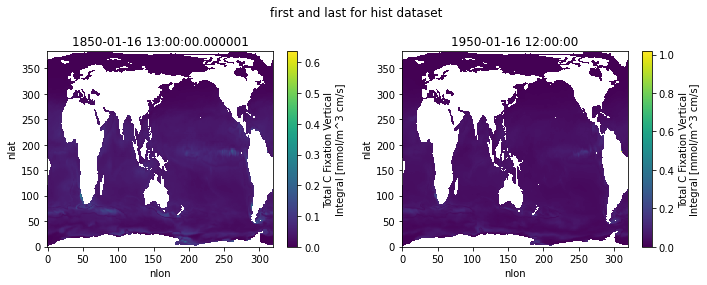

In [17]:
mem_5_hist = ds_hist.photoC_TOT_zint.isel(member_id=5)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

mem_5_hist.isel(time=0).plot(ax=ax1)
ax1.set_title(mem_5_hist.isel(time=0).time.values)

mem_5_hist.isel(time=1200).plot(ax=ax2)
ax2.set_title(mem_5_hist.isel(time=1200).time.values)

fig.suptitle("first and last for hist dataset")

plt.tight_layout()
plt.show()

### Load future data

In [18]:
%%time
# load historical
ds_ssp = load_datasets(varnames,'ssp370')
# preprocess if some variables need depth averaging
ds_ssp = preprocess(ds_ssp)
ds_ssp


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


CPU times: user 9.62 s, sys: 133 ms, total: 9.76 s
Wall time: 13 s


<xarray.Dataset>
Dimensions:          (d2: 2, member_id: 50, nlat: 384, nlon: 320, time: 1032, z_t: 60, z_t_150m: 15)
Coordinates:
  * z_t              (z_t) float32 500.0 1.5e+03 2.5e+03 ... 5.125e+05 5.375e+05
  * z_t_150m         (z_t_150m) float32 500.0 1.5e+03 ... 1.35e+04 1.45e+04
    TLONG            (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    TLAT             (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
  * time             (time) object 2015-01-16 13:00:00.000001 ... 2100-12-16 ...
Dimensions without coordinates: d2, member_id, nlat, nlon
Data variables:
    KMT              (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    time_bound       (time, d2) object dask.array<chunksize=(120, 2), meta=np.ndarray>
    photoC_TOT_zint  (member_id, time, nlat, nlon) float32 dask.array<chunksize=(1, 120, 384, 320), meta=np.ndarray>

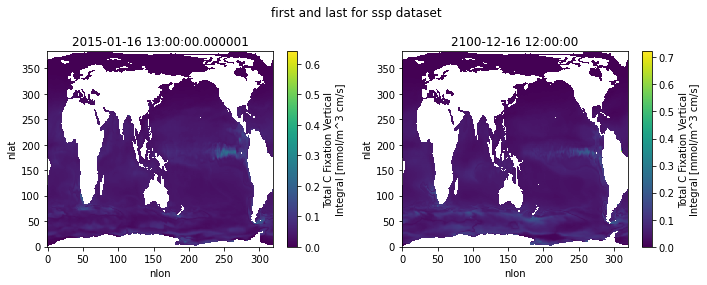

In [19]:
mem_5_ssp = ds_ssp.photoC_TOT_zint.isel(member_id=5)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

mem_5_ssp.isel(time=0).plot(ax=ax1)
ax1.set_title(mem_5_ssp.isel(time=0).time.values)

mem_5_ssp.isel(time=-1).plot(ax=ax2)
ax2.set_title(mem_5_ssp.isel(time=-1).time.values)

fig.suptitle("first and last for ssp dataset")

plt.tight_layout()
plt.show()

## Concatenate historical and future datasets, keep just years of interest

In [20]:
ds = xr.concat((ds_hist, ds_ssp),dim='time')
ds.time

<xarray.DataArray 'time' (time: 3012)>
array([cftime.DatetimeNoLeap(1850, 1, 16, 13, 0, 0, 1),
       cftime.DatetimeNoLeap(1850, 2, 15, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(1850, 3, 16, 12, 0, 0, 0), ...,
       cftime.DatetimeNoLeap(2100, 10, 16, 12, 0, 0, 0),
       cftime.DatetimeNoLeap(2100, 11, 16, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(2100, 12, 16, 12, 0, 0, 0)], dtype=object)
Coordinates:
  * time     (time) object 1850-01-16 13:00:00.000001 ... 2100-12-16 12:00:00
Attributes:
    long_name:  boundaries for time-averaging interval

### Convert to annual means

In [21]:
ds = ds.resample({'time':'A'}).mean(dim='time').compute()

In [28]:
ds['time'] = np.arange(1850,2101,1)

### Do ToE analysis

In [29]:
time3d = np.full([251,384,320],1,dtype=int)

In [30]:
ylen = 384
xlen = 320

for x in np.arange(0,xlen,1):
    for y in np.arange(0,ylen,1):

        time3d[:,y,x]=ds.time.values

time3d = xr.DataArray(time3d,dims=('time','nlat','nlon'))

In [31]:
ds

<xarray.Dataset>
Dimensions:          (member_id: 50, nlat: 384, nlon: 320, time: 251, z_t: 60, z_t_150m: 15)
Coordinates:
  * time             (time) int64 1850 1851 1852 1853 ... 2097 2098 2099 2100
  * z_t              (z_t) float32 500.0 1.5e+03 2.5e+03 ... 5.125e+05 5.375e+05
  * z_t_150m         (z_t_150m) float32 500.0 1.5e+03 ... 1.35e+04 1.45e+04
    TLONG            (nlat, nlon) float64 320.6 321.7 322.8 ... 319.4 319.8
    TLAT             (nlat, nlon) float64 -79.22 -79.22 -79.22 ... 72.19 72.19
Dimensions without coordinates: member_id, nlat, nlon
Data variables:
    KMT              (time, nlat, nlon) float64 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    photoC_TOT_zint  (time, member_id, nlat, nlon) float32 nan nan ... nan nan

In [32]:
%%time

#HISTORICAL PERIOD = 1850 - 1899 (50 years)

upthres_ds = xr.Dataset()
lothres_ds = xr.Dataset()

variables=['photoC_TOT_zint']

for var in variables:
    
    ### calculate                                                                                                                                                                                                                                                                 
    mean_var = ds[var].isel(time=slice(0,50)).mean(dim=('time','member_id'))
    std_var = ds[var].isel(time=slice(0,50)).std(dim=('member_id','time'))
    
    var_array_upthres = mean_var + 2 * std_var
    var_array_lothres = mean_var - 2 * std_var

    upthres_ds[var] = var_array_upthres
    lothres_ds[var] = var_array_lothres

CPU times: user 1.2 s, sys: 285 ms, total: 1.49 s
Wall time: 1.46 s


In [33]:
ToE_up = time3d.where(ds.photoC_TOT_zint.mean(dim='member_id') > upthres_ds['photoC_TOT_zint'])
ToE_up = ToE_up.min(dim='time')

In [35]:
ToE_down = time3d.where(ds.photoC_TOT_zint.mean(dim='member_id') < lothres_ds['photoC_TOT_zint'])
ToE_down = ToE_down.min(dim='time')

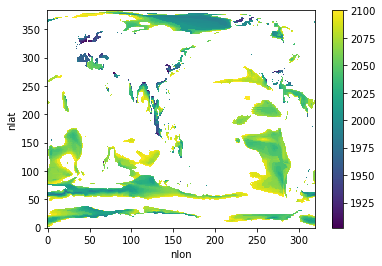

In [36]:
ToE_up.plot()

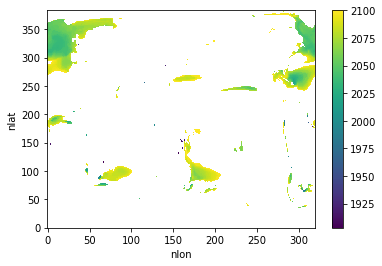

In [37]:
ToE_down.plot()

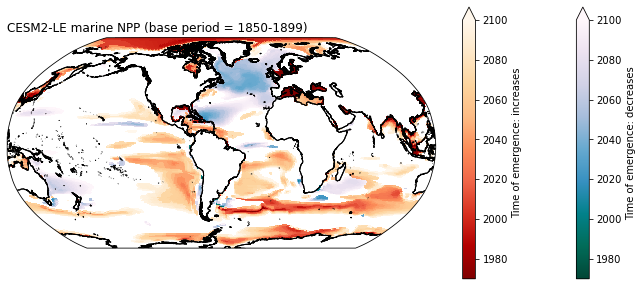

In [40]:
fig = plt.figure(figsize=(12,5))

############### 
ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))

ax.set_title('CESM2-LE marine NPP (base period = 1850-1899)', loc='left')

lon,lat,field = utils.adjust_pop_grid(lons, lats, ToE_down)
pc = ax.pcolormesh(lon,lat,field,
                    transform=ccrs.PlateCarree(),cmap='PuBuGn_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: decreases');

lon,lat,field = utils.adjust_pop_grid(lons, lats, ToE_up)
pc = ax.pcolormesh(lon,lat,field,
                    transform=ccrs.PlateCarree(),cmap='OrRd_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: increases');

#fig.savefig('/glade/work/kristenk/figs/CESM2-LE-ToE-marine_NPP.png', bbox_inches='tight', dpi=300, format='png');

### Make a global timeseries

In [43]:
npp = ds.photoC_TOT_zint * 0.01 * 86400 * 365 * 0.001 * 12 #g/m2/y
area_m2 = area * 0.0001

glb_npp = (npp * area_m2).sum(dim=('nlon','nlat')) * 1e-15 #Pg C/yr

In [50]:

#SIZ
mean = glb_npp.isel(time=slice(0,50)).mean(dim=('time','member_id')).values
std = glb_npp.isel(time=slice(0,50)).std(dim=('time','member_id')).values
toe_npp = glb_npp.time.where(glb_npp.mean(dim='member_id') > mean+2*std).min(dim='time')
toe_npp_val = mean-2*std
print(toe_npp, toe_npp_val)

<xarray.DataArray 'time' ()>
array(2028.) 47.38831545859903


Text(0.5, 0, 'Year')

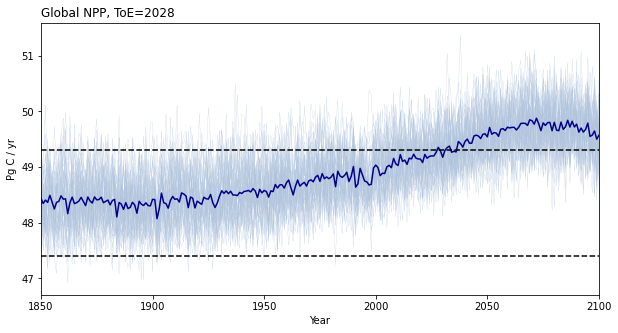

In [51]:
fig = plt.figure(figsize=(10,5))

#################
ax = fig.add_subplot(1, 1, 1)
ax.set_title("Global NPP, ToE=2028", loc="left", fontsize=12)

for mem in np.arange(0,50,1):

    ax.plot(glb_npp.time, glb_npp.isel(member_id=mem), color='lightsteelblue',linewidth=0.2)
    
ax.plot(glb_npp.time, glb_npp.mean(dim='member_id'),
           color='darkblue', zorder=2)
std_up = (glb_npp.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time')+ 2*glb_npp.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
std_down = (glb_npp.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time')- 2*glb_npp.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
ax.axhline(std_up, linestyle='--',color='black')
ax.axhline(std_down, linestyle='--',color='black')
ax.set_xlim(1850,2100)
#ax.set_ylim(13,20)
ax.set_ylabel('Pg C / yr')
ax.set_xlabel('Year')

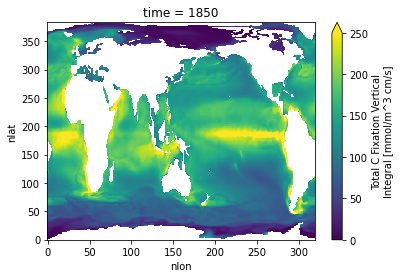

In [56]:
npp.isel(member_id=0,time=0).plot(vmin=0,vmax=250)

### Get data ready for writing out

In [59]:
ds_out = xr.Dataset()

ds_out['marineNPP_ens_mean'] = ds['photoC_TOT_zint'].mean(dim='member_id') * 0.01 * 86400 * 365 * 0.001 * 12 #g/m2/y
ds_out['marineNPP_ens_mean'].attrs = ds.photoC_TOT_zint.attrs
ds_out['marineNPP_ens_mean'].attrs['units'] = 'gC/m2/y'
ds_out['marineNPP_ens_mean'].attrs['notes'] = 'ensemble mean of 50 cmip6 forcing ensemble members'

ds_out['marineNPP_st_dev'] = ds['photoC_TOT_zint'].std(dim='member_id') * 0.01 * 86400 * 365 * 0.001 * 12 #g/m2/y
ds_out['marineNPP_st_dev'].attrs = ds.photoC_TOT_zint.attrs
ds_out['marineNPP_st_dev'].attrs['units'] = 'gC/m2/y'
ds_out['marineNPP_st_dev'].attrs['notes'] = 'ensemble standard deviation of 50 cmip6 forcing ensemble members'

ds_out.attrs['author'] = 'Kristen Krumhardt'
ds_out.attrs['date_processed'] = datetime.now().strftime('%Y-%m-%d')
ds_out.attrs['contents'] = f'Marine NPP from CESM2-LE'

ds_out

<xarray.Dataset>
Dimensions:             (nlat: 384, nlon: 320, time: 251)
Coordinates:
  * time                (time) int64 1850 1851 1852 1853 ... 2097 2098 2099 2100
    TLONG               (nlat, nlon) float64 320.6 321.7 322.8 ... 319.4 319.8
    TLAT                (nlat, nlon) float64 -79.22 -79.22 ... 72.19 72.19
Dimensions without coordinates: nlat, nlon
Data variables:
    marineNPP_ens_mean  (time, nlat, nlon) float64 nan nan nan ... nan nan nan
    marineNPP_st_dev    (time, nlat, nlon) float64 nan nan nan ... nan nan nan
Attributes:
    author:          Kristen Krumhardt
    date_processed:  2026-10-26
    contents:        Marine NPP from CESM2-LE

In [60]:
# calculate the size of the dataset in GB
size_gb = ds_out.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 0.46 GB.


In [61]:
path_out = '/glade/derecho/scratch/kristenk/ToE_saved_data/'
file_out = 'CESM2-LE-marine_NPP_ens_mean_std.nc'
fout = path_out + file_out